# Diffusion Monte Carlo

Imaginary-time Schrödinger equation, $\hbar = m = 1$:

$$-\partial_\tau \psi = \left[-\tfrac12\nabla^2 + V - E_T\right]\psi .$$

Every excited component decays like $e^{-(E_n - E_0)\tau}$ relative to the ground state, so a long
enough run projects out $\psi_0$. `dmc.py` runs it as a crowd of walkers. Each step:

1. every walker diffuses, $x \to x + \sqrt{\Delta\tau}\,\xi$;
2. it gets the weight $w = e^{-(V - E_T)\Delta\tau}$;
3. it becomes $\lfloor w + u\rfloor$ copies;
4. $E_T = \langle V\rangle - (\kappa/\Delta\tau)\ln(N/N_\text{target})$ steers the population.

There is no importance sampling and no trial wavefunction, so the walker density is $\psi_0$
itself.

The other files:

- `reference.py`: exact answers, including the exact finite-$\Delta\tau$ oscillator results.
- `errors.py`: last week's binning error bars.
- `test_dmc.py`: fast unit checks.

Each section ends with printed **CHECK** lines, and section 6 collects them.

Two energy estimators run side by side:

- **The growth energy, $\langle E_T\rangle$.** The population is stationary only if $E_T$
  matches the decay rate.
- **The walker average $\langle V\rangle$.** Integrating $H\psi_0 = E_0\psi_0$ over all space
  kills the kinetic term, which is a total derivative. That leaves
  $\int V\psi_0 = E_0\int\psi_0$, so averaging $V$ over a density $\propto\psi_0$ gives $E_0$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from dmc import run, harmonic, coulomb
from errors import binned_error
from reference import (s, V_exact, ET_exact, psi0_pdf, psi0sq_pdf, psi1_half, h_radial_psi,
                       h_radial_psi2, transfer_kernel)

checks = {}
def check(name, ok):
    checks[name] = bool(ok)
    print(f"CHECK {name}:", "PASS" if ok else "FAIL")

def measure(r, burn, min_bins=32):
    # mean and binned error of both estimators, after discarding the projection transient;
    # the largest block must reach the binning plateau (blocks >~ 10 units of tau for hydrogen)
    return {k: (r[k][burn:].mean(), binned_error(r[k][burn:], min_bins)) for k in ("ET", "Vmean")}

def fit_intercept(x, y, e, deg):
    # weighted polynomial fit; returns coefficients, the value at x = 0, and its error
    p, cov = np.polyfit(x, y, deg, w=1 / e, cov="unscaled")
    return p, p[-1], np.sqrt(cov[-1, -1])

N_T = 4000          # target population everywhere

## 1. Watching the energy converge

The potential is $V = x^2/2$ and the step is $\Delta\tau = 0.1$. The walkers start deliberately
wrong, uniform on $[-4, 4]$, where $\langle V\rangle = 8/3$. Both estimators fall onto the exact
$E_0 = 1/2$ within a few units of imaginary time. That is the gap $E_2 - E_0 = 2$ at work. The
start is symmetric, so the odd state $E_1$ is suppressed.

The plot shows the first 20 units. The run continues to $\tau = 1000$, and everything after
$\tau = 20$ is averaged.

The bottom panel is the population, steered back to $N_\text{target}$ by $E_T$. The early
overshoot is $E_T$ starting high and cooling with $\langle V\rangle$.

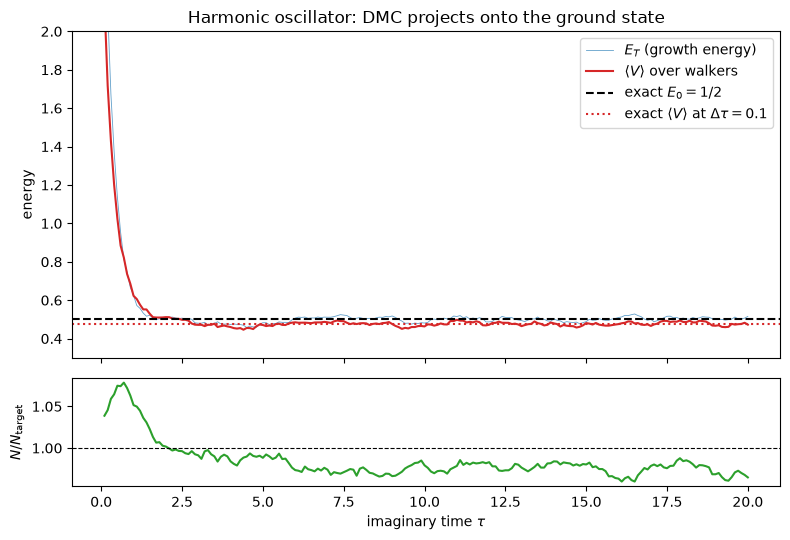

ET     = 0.49968 ± 0.00037   exact at dtau = 0.1: 0.499792   z = -0.30
Vmean  = 0.47523 ± 0.00033   exact at dtau = 0.1: 0.475625   z = -1.18
CHECK 1a (E_T within 4 sigma of asinh(dtau/2)/dtau): PASS
CHECK 1b (<V> within 4 sigma of s/2): PASS
CHECK 1c (population mean within 5% of target after the transient): PASS


In [2]:
dt1, T1, burn1 = 0.1, 1000, 200
rng = np.random.default_rng(0)
r1 = run(harmonic, rng.uniform(-4, 4, N_T), dt1, int(T1 / dt1), N_T, seed=1, keep_from=burn1)
m1 = measure(r1, burn1)

show = r1["tau"] <= 20
fig, (a1, a2) = plt.subplots(2, 1, figsize=(8, 5.5), sharex=True,
                             gridspec_kw=dict(height_ratios=[3, 1]))
a1.plot(r1["tau"][show], r1["ET"][show], lw=0.6, color="C0", alpha=0.7, label=r"$E_T$ (growth energy)")
a1.plot(r1["tau"][show], r1["Vmean"][show], lw=1.5, color="C3", label=r"$\langle V\rangle$ over walkers")
a1.axhline(0.5, ls="--", color="k", label=r"exact $E_0 = 1/2$")
a1.axhline(V_exact(dt1), ls=":", color="C3", label=rf"exact $\langle V\rangle$ at $\Delta\tau={dt1}$")
a1.set_ylim(0.3, 2.0); a1.set_ylabel("energy"); a1.legend(loc="upper right")
a1.set_title(r"Harmonic oscillator: DMC projects onto the ground state")
a2.plot(r1["tau"][show], r1["N"][show] / N_T, color="C2")
a2.axhline(1, ls="--", color="k", lw=0.8)
a2.set_ylabel(r"$N / N_\mathrm{target}$"); a2.set_xlabel(r"imaginary time $\tau$")
plt.tight_layout(); plt.show()

for k, ex in (("ET", ET_exact(dt1)), ("Vmean", V_exact(dt1))):
    mu, e = m1[k]
    print(f"{k:6s} = {mu:.5f} ± {e:.5f}   exact at dtau = {dt1}: {ex:.6f}   z = {(mu - ex) / e:+.2f}")
check("1a (E_T within 4 sigma of asinh(dtau/2)/dtau)", abs(m1["ET"][0] - ET_exact(dt1)) < 4 * m1["ET"][1])
check("1b (<V> within 4 sigma of s/2)", abs(m1["Vmean"][0] - V_exact(dt1)) < 4 * m1["Vmean"][1])
check("1c (population mean within 5% of target after the transient)", abs(r1["N"][burn1:].mean() / N_T - 1) < 0.05)

The two estimators disagree at finite $\Delta\tau$, and they disagree by exactly the predicted
amounts. Everything in one step is Gaussian, so the walker density after branching is a Gaussian
whose variance $s$ satisfies $1/s = 1/(s + \Delta\tau) + \Delta\tau$. This gives

$$\langle V\rangle_{\Delta\tau} = \frac{s}{2} = \frac12 - \frac{\Delta\tau}{4} + \frac{\Delta\tau^2}{16} + \dots,
\qquad \langle E_T\rangle_{\Delta\tau} = \frac{\operatorname{asinh}(\Delta\tau/2)}{\Delta\tau} = \frac{\tilde\omega}{2} = \frac12 - \frac{\Delta\tau^2}{48} + \dots$$

Here $\tilde\omega$ is last week's lattice frequency, $\cosh(\Delta\tau\,\tilde\omega) = 1 + \Delta\tau^2/2$.
One DMC step is one time slice of the path integral. Both formulas are checked against a direct
diagonalization of the one-step kernel on a grid:

In [3]:
for d in (0.4, 0.1):
    E, var = transfer_kernel(d)
    print(f"dtau = {d}:  kernel E = {E:.8f}  asinh formula = {ET_exact(d):.8f} | kernel var = {var:.8f}  s = {s(d):.8f}")

dtau = 0.4:  kernel E = 0.49672528  asinh formula = 0.49672528 | kernel var = 0.81980390  s = 0.81980390


dtau = 0.1:  kernel E = 0.49979190  asinh formula = 0.49979190 | kernel var = 0.95124922  s = 0.95124922


## 2. The walkers are $\psi_0$, not $|\psi_0|^2$

Here are the walker positions pooled from $\tau = 20$ to $1000$. They are drawn against two
curves:

- $\psi_0$ normalized as a density, a standard normal with $\sigma = 1$;
- $|\psi_0|^2$, with $\sigma = 1/\sqrt2$.

Metropolis-based methods (variational MC, last week's PIMC) sample $|\psi|^2$. DMC never squares
anything, and the histogram sits on the wide curve.

At finite $\Delta\tau$ the width is $\sqrt{s}$, slightly under 1. That is the time-step error
showing up in the shape, and it is the same number that sets $\langle V\rangle$.

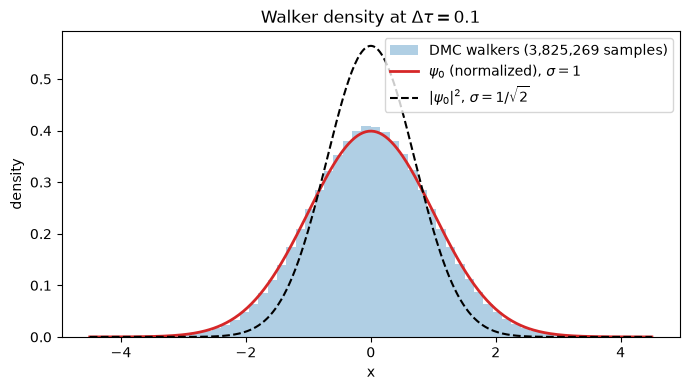

walker variance 0.9511; exact finite-dtau s = 0.9512; psi_0: 1; |psi_0|^2: 0.5
L1 distance of histogram to psi_0: 0.0236, to |psi_0|^2: 0.3075
CHECK 2a (walker variance within 1% of s(dtau)): PASS
CHECK 2b (histogram 10x closer to psi_0 than to |psi_0|^2): PASS


In [4]:
xs = r1["samples"][:, 0]
grid = np.linspace(-4.5, 4.5, 400)
counts, edges = np.histogram(xs, bins=60, range=(-4.5, 4.5), density=True)
mid = 0.5 * (edges[1:] + edges[:-1])

plt.figure(figsize=(7, 4))
plt.stairs(counts, edges, fill=True, alpha=0.35, color="C0", label=f"DMC walkers ({len(xs):,} samples)")
plt.plot(grid, psi0_pdf(grid), color="C3", lw=2, label=r"$\psi_0$ (normalized), $\sigma = 1$")
plt.plot(grid, psi0sq_pdf(grid), color="k", ls="--", lw=1.5, label=r"$|\psi_0|^2$, $\sigma = 1/\sqrt{2}$")
plt.xlabel("x"); plt.ylabel("density"); plt.legend()
plt.title(r"Walker density at $\Delta\tau = 0.1$")
plt.tight_layout(); plt.show()

var = xs.var()
L1 = lambda f: np.abs(counts - f(mid)).sum() * (mid[1] - mid[0])
print(f"walker variance {var:.4f}; exact finite-dtau s = {s(dt1):.4f}; psi_0: 1; |psi_0|^2: 0.5")
print(f"L1 distance of histogram to psi_0: {L1(psi0_pdf):.4f}, to |psi_0|^2: {L1(psi0sq_pdf):.4f}")
check("2a (walker variance within 1% of s(dtau))", abs(var / s(dt1) - 1) < 0.01)
check("2b (histogram 10x closer to psi_0 than to |psi_0|^2)", 10 * L1(psi0_pdf) < L1(psi0sq_pdf))

## 3. Removing the time-step error

The step sizes are $\Delta\tau = 0.4, 0.2, 0.1, 0.05$, with the total imaginary time held at
1000 so every run projects equally far. Each estimator is compared with its exact finite-$\Delta\tau$
curve, and each is then extrapolated to $\Delta\tau \to 0$ in the form its expansion dictates:

- **$\langle V\rangle$** has a first-order error, but a straight line is not enough. The
  $\Delta\tau^2/16$ term would pull it to $0.4979$, many error bars off. So the fit is
  $a + b\,\Delta\tau + c\,\Delta\tau^2$.
- **$E_T$** has no first-order term, so the fit is $a + c\,\Delta\tau^2$. The reason is that the
  primitive step $e^{-\Delta\tau V}e^{-\Delta\tau T}$ has the same eigenvalues as the symmetric
  split $e^{-\Delta\tau V/2}e^{-\Delta\tau T}e^{-\Delta\tau V/2}$, whose error is second order.

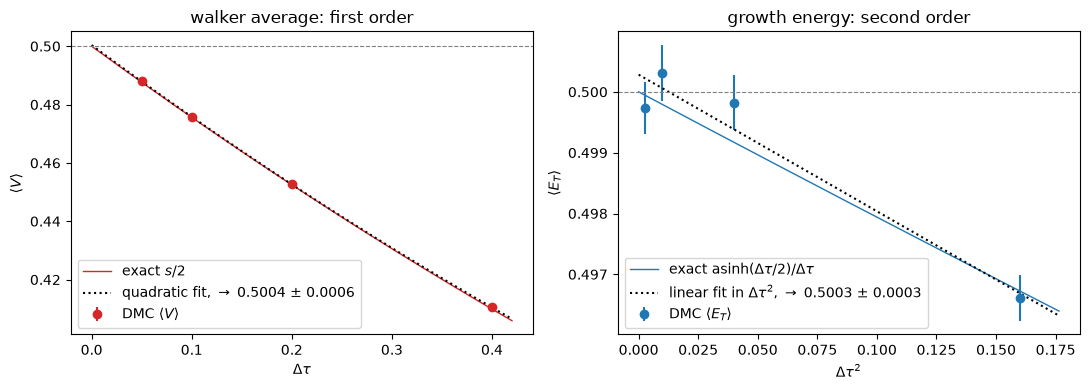

dtau =  0.4:  <V> = 0.41045 ± 0.00040 (exact 0.40990)   E_T = 0.49661 ± 0.00037 (exact 0.49673)
dtau =  0.2:  <V> = 0.45265 ± 0.00042 (exact 0.45249)   E_T = 0.49982 ± 0.00045 (exact 0.49917)
dtau =  0.1:  <V> = 0.47581 ± 0.00035 (exact 0.47562)   E_T = 0.50031 ± 0.00046 (exact 0.49979)
dtau = 0.05:  <V> = 0.48793 ± 0.00039 (exact 0.48766)   E_T = 0.49973 ± 0.00043 (exact 0.49995)
straight line through the exact <V> values would give 0.4979
CHECK 3a (every <V> point within 3 sigma of s/2): PASS
CHECK 3b (every E_T point within 3 sigma of asinh formula): PASS
CHECK 3c (<V> quadratic extrapolation within 3 sigma of 1/2): PASS
CHECK 3d (E_T extrapolation in dtau^2 within 3 sigma of 1/2): PASS


In [5]:
dts = np.array([0.4, 0.2, 0.1, 0.05])
sweep = []
for i, d in enumerate(dts):
    burn = int(20 / d)
    r = run(harmonic, rng.uniform(-4, 4, N_T), d, int(1000 / d), N_T, seed=10 + i)
    sweep.append(measure(r, burn))
ET_m, ET_e = np.array([m["ET"] for m in sweep]).T
V_m, V_e = np.array([m["Vmean"] for m in sweep]).T

pV, aV, eV = fit_intercept(dts, V_m, V_e, 2)
pE, aE, eE = fit_intercept(dts**2, ET_m, ET_e, 1)
lin_exact = np.polyfit(dts, V_exact(dts), 1)[-1]

g = np.linspace(0, 0.42, 200)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4))
a1.errorbar(dts, V_m, V_e, fmt="o", color="C3", label=r"DMC $\langle V\rangle$")
a1.plot(g, V_exact(g), color="C3", lw=1, label=r"exact $s/2$")
a1.plot(g, np.polyval(pV, g), "k:", label=rf"quadratic fit, $\to$ {aV:.4f} ± {eV:.4f}")
a1.axhline(0.5, ls="--", color="gray", lw=0.8)
a1.set_xlabel(r"$\Delta\tau$"); a1.set_ylabel(r"$\langle V\rangle$"); a1.legend(); a1.set_title("walker average: first order")
a2.errorbar(dts**2, ET_m, ET_e, fmt="o", color="C0", label=r"DMC $\langle E_T\rangle$")
a2.plot(g**2, ET_exact(g + 1e-12), color="C0", lw=1, label=r"exact asinh$(\Delta\tau/2)/\Delta\tau$")
a2.plot(g**2, np.polyval(pE, g**2), "k:", label=rf"linear fit in $\Delta\tau^2$, $\to$ {aE:.4f} ± {eE:.4f}")
a2.axhline(0.5, ls="--", color="gray", lw=0.8)
a2.set_xlabel(r"$\Delta\tau^2$"); a2.set_ylabel(r"$\langle E_T\rangle$"); a2.legend(); a2.set_title("growth energy: second order")
plt.tight_layout(); plt.show()

for d, (vm, ve), (em, ee) in zip(dts, zip(V_m, V_e), zip(ET_m, ET_e)):
    print(f"dtau = {d:4}:  <V> = {vm:.5f} ± {ve:.5f} (exact {V_exact(d):.5f})   "
          f"E_T = {em:.5f} ± {ee:.5f} (exact {ET_exact(d):.5f})")
print(f"straight line through the exact <V> values would give {lin_exact:.4f}")
check("3a (every <V> point within 3 sigma of s/2)", np.all(np.abs(V_m - V_exact(dts)) < 3 * V_e))
check("3b (every E_T point within 3 sigma of asinh formula)", np.all(np.abs(ET_m - ET_exact(dts)) < 3 * ET_e))
check("3c (<V> quadratic extrapolation within 3 sigma of 1/2)", abs(aV - 0.5) < 3 * eV)
check("3d (E_T extrapolation in dtau^2 within 3 sigma of 1/2)", abs(aE - 0.5) < 3 * eE)

## 4. Hydrogen

The walkers now live in 3D, with $V = -1/r$. The exact answers are $E_0 = -1/2$ and
$\psi_0 \propto e^{-r}$. Nothing in `dmc.py` changes except the potential and the shape of the
walker array.

The new problem is the Coulomb singularity. A walker that lands near $r = 0$ gets the weight
$e^{\Delta\tau/r}$, which is unbounded. The expected weight $\int r^2 e^{\Delta\tau/r}\,dr$
even diverges. So the number of copies per walker is capped, at `max_copies = 10`. A cap biases
the answer only if it actually bites. There is no uncapped run to compare with, so the test is
to rerun with a harsher cap (3) and a looser one (50).

The radial histogram is compared with two densities:

- $\tfrac12 r^2 e^{-r}$ for $\psi_0$, which peaks at $r = 2$ and has $\langle r\rangle = 3$;
- $4r^2e^{-2r}$ for $|\psi_0|^2$, which peaks at $r = 1$ and has $\langle r\rangle = 3/2$.

The error bars need more care than for the oscillator. The lowest excitation of hydrogen,
$E_2 - E_1 = 3/8$, is much smaller than the oscillator's gap of 2. So the walker crowd remembers
its past for several units of $\tau$, and the binning curve only plateaus at blocks of about
10 to 20 units. The runs are therefore $\tau = 600$ long and binned down to 16 blocks.
A seed sweep confirmed the fix. With 32 blocks on $\tau = 300$ runs, the error bars came out
25% too small.

In [6]:
dtH = np.array([0.08, 0.04, 0.02, 0.01, 0.005])
TH, cap = 600, 10
hyd = []
for i, d in enumerate(dtH):
    burn = int(20 / d)
    r = run(coulomb, rng.normal(0, 1.5, (N_T, 3)), d, int(TH / d), N_T, seed=20 + i,
            max_copies=cap, keep_from=burn, keep_every=max(1, int(0.5 / d)))
    hyd.append((r, measure(r, burn, min_bins=16)))
HE_m, HE_e = np.array([m["ET"] for _, m in hyd]).T
HV_m, HV_e = np.array([m["Vmean"] for _, m in hyd]).T

# the same runs with a harsher (3) and a looser (50) cap, at the three largest steps
caps = {}
for cap_alt in (3, 50):
    for i, d in enumerate(dtH[:3]):
        r = run(coulomb, rng.normal(0, 1.5, (N_T, 3)), d, int(TH / d), N_T, seed=40 + i + 10 * cap_alt,
                max_copies=cap_alt)
        caps[cap_alt, d] = (measure(r, int(20 / d), min_bins=16)["ET"], r["n_capped"] / len(r["ET"]))
for i, d in enumerate(dtH[:3]):
    caps[cap, d] = (hyd[i][1]["ET"], hyd[i][0]["n_capped"] / len(hyd[i][0]["ET"]))
    print(f"dtau = {d}:  " + "   ".join(
        f"cap {c:2d}: E_T = {caps[c, d][0][0]:.4f} ± {caps[c, d][0][1]:.4f} ({caps[c, d][1]:.4f} capped/step)"
        for c in (3, cap, 50)))

dtau = 0.08:  cap  3: E_T = -0.5022 ± 0.0014 (0.1224 capped/step)   cap 10: E_T = -0.5067 ± 0.0014 (0.0205 capped/step)   cap 50: E_T = -0.5131 ± 0.0014 (0.0035 capped/step)
dtau = 0.04:  cap  3: E_T = -0.5037 ± 0.0012 (0.0167 capped/step)   cap 10: E_T = -0.5035 ± 0.0012 (0.0026 capped/step)   cap 50: E_T = -0.5076 ± 0.0015 (0.0008 capped/step)
dtau = 0.02:  cap  3: E_T = -0.5027 ± 0.0010 (0.0024 capped/step)   cap 10: E_T = -0.4983 ± 0.0012 (0.0003 capped/step)   cap 50: E_T = -0.5024 ± 0.0012 (0.0001 capped/step)


The cap is not innocent at large $\Delta\tau$. At $\Delta\tau = 0.08$ a looser cap gives a *lower*
energy, and there is no limit to converge to. That is the divergent expected weight: at finite
$\Delta\tau$ the uncapped answer does not exist. The effect is set by how often a walker lands
within $r \lesssim \Delta\tau/\ln(\text{cap})$ of the nucleus. That probability falls like
$\Delta\tau^3$, so the cap dependence dies off quickly, and it is gone by $\Delta\tau = 0.02$. The
cap therefore belongs to the time-step error. It disappears in the same $\Delta\tau \to 0$
extrapolation, and what has to be checked is that it is negligible at the small steps that anchor
that extrapolation.

In [7]:
def cap_z(c, d):
    (a, e), (b, f) = caps[c, d][0], caps[cap, d][0]
    return abs(a - b) / np.hypot(e, f)
spread = [abs(caps[50, d][0][0] - caps[3, d][0][0]) for d in dtH[:3]]
cap_z_pair = lambda d: abs(caps[50, d][0][0] - caps[3, d][0][0]) / np.hypot(caps[50, d][0][1], caps[3, d][0][1])
print("cap-3 vs cap-50 spread in E_T:", "  ".join(f"dtau={d}: {x:.4f}" for d, x in zip(dtH[:3], spread)))

cap-3 vs cap-50 spread in E_T: dtau=0.08: 0.0108  dtau=0.04: 0.0039  dtau=0.02: 0.0003


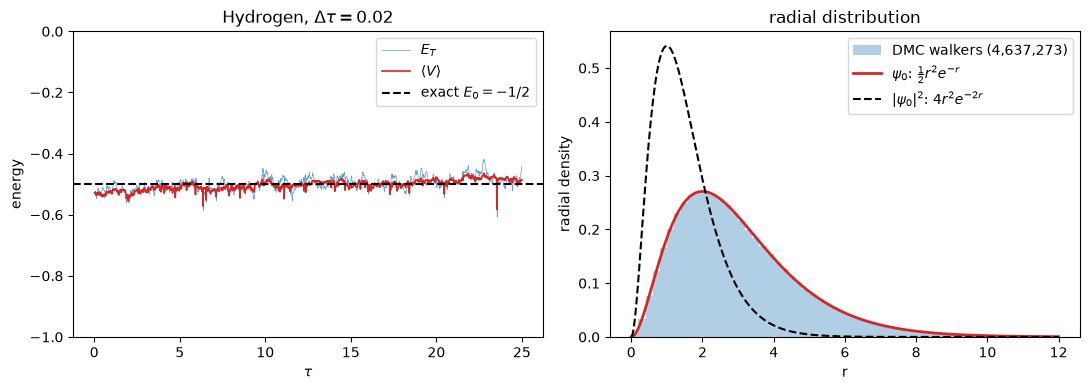

<r> = 3.004  (psi_0: 3, |psi_0|^2: 1.5)
L1 distance to psi_0: 0.0043, to |psi_0|^2: 0.8780


In [8]:
rH, _ = hyd[2]                                   # dtau = 0.02 for the pictures
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4))
show = rH["tau"] <= 25
a1.plot(rH["tau"][show], rH["ET"][show], lw=0.5, color="C0", alpha=0.7, label=r"$E_T$")
a1.plot(rH["tau"][show], rH["Vmean"][show], lw=1.2, color="C3", label=r"$\langle V\rangle$")
a1.axhline(-0.5, ls="--", color="k", label=r"exact $E_0 = -1/2$")
a1.set_ylim(-1.0, 0.0); a1.set_xlabel(r"$\tau$"); a1.set_ylabel("energy"); a1.legend()
a1.set_title(r"Hydrogen, $\Delta\tau = 0.02$")
rr = np.linalg.norm(rH["samples"], axis=1)
rg = np.linspace(0, 12, 400)
cH, eH = np.histogram(rr, bins=60, range=(0, 12), density=True)
a2.stairs(cH, eH, fill=True, alpha=0.35, color="C0", label=f"DMC walkers ({len(rr):,})")
a2.plot(rg, h_radial_psi(rg), color="C3", lw=2, label=r"$\psi_0$: $\frac{1}{2}r^2e^{-r}$")
a2.plot(rg, h_radial_psi2(rg), "k--", lw=1.5, label=r"$|\psi_0|^2$: $4r^2e^{-2r}$")
a2.set_xlabel("r"); a2.set_ylabel("radial density"); a2.legend(); a2.set_title("radial distribution")
plt.tight_layout(); plt.show()

midH = 0.5 * (eH[1:] + eH[:-1])
L1H = lambda f: np.abs(cH - f(midH)).sum() * (midH[1] - midH[0])
print(f"<r> = {rr.mean():.3f}  (psi_0: 3, |psi_0|^2: 1.5)")
print(f"L1 distance to psi_0: {L1H(h_radial_psi):.4f}, to |psi_0|^2: {L1H(h_radial_psi2):.4f}")

Plain DMC on hydrogen has a visible time-step error, worse than the oscillator's because of the
singularity. Unlike the oscillator, there is no exact finite-$\Delta\tau$ curve to lean on, so
choosing which points to fit, and with what form, is a judgement read off the data.

The cap study above settles which points to use. At $\Delta\tau = 0.08$ and $0.04$ the result
still depends on the cap, by up to $0.015$, so those points carry a bias that has nothing to do
with a smooth expansion in $\Delta\tau$. They are plotted as open symbols and left out of the
fit. At $\Delta\tau \le 0.02$ the cap is negligible (check 4c). Over those three points both
estimators are consistent with a straight line, so the fit is a weighted line in $\Delta\tau$.

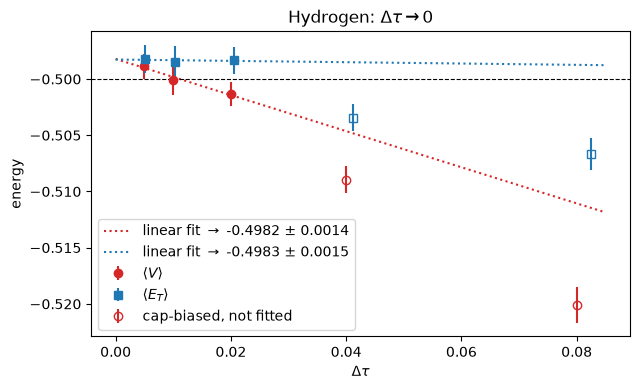

dtau = 0.08:  <V> = -0.5201 ± 0.0016   E_T = -0.5067 ± 0.0014
dtau = 0.04:  <V> = -0.5089 ± 0.0012   E_T = -0.5035 ± 0.0012
dtau = 0.02:  <V> = -0.5014 ± 0.0011   E_T = -0.4983 ± 0.0012
dtau = 0.01:  <V> = -0.5001 ± 0.0013   E_T = -0.4985 ± 0.0015
dtau = 0.005:  <V> = -0.4989 ± 0.0011   E_T = -0.4982 ± 0.0012
CHECK 4a (<V> extrapolation within 3 sigma of -1/2): PASS
CHECK 4b (E_T extrapolation within 3 sigma of -1/2): PASS
CHECK 4c (at dtau = 0.02, caps 3 and 50 agree with cap 10 within 3 sigma): PASS
CHECK 4d (at dtau = 0.08 the cap does bite: caps 3 and 50 differ by > 3 sigma): PASS
CHECK 4e (<r> within 2% of 3, the psi_0 value): PASS
CHECK 4f (radial histogram 10x closer to psi_0 than to |psi_0|^2): PASS


In [9]:
fit = dtH <= 0.02                                # where the cap no longer matters (check 4c)
pHV, aHV, eHV = fit_intercept(dtH[fit], HV_m[fit], HV_e[fit], 1)
pHE, aHE, eHE = fit_intercept(dtH[fit], HE_m[fit], HE_e[fit], 1)
g = np.linspace(0, 0.085, 100)
plt.figure(figsize=(6.5, 4))
plt.errorbar(dtH[fit], HV_m[fit], HV_e[fit], fmt="o", color="C3", label=r"$\langle V\rangle$")
plt.errorbar(dtH[fit] * 1.03, HE_m[fit], HE_e[fit], fmt="s", color="C0", label=r"$\langle E_T\rangle$")
plt.errorbar(dtH[~fit], HV_m[~fit], HV_e[~fit], fmt="o", mfc="none", color="C3", label="cap-biased, not fitted")
plt.errorbar(dtH[~fit] * 1.03, HE_m[~fit], HE_e[~fit], fmt="s", mfc="none", color="C0")
plt.plot(g, np.polyval(pHV, g), "C3:", label=rf"linear fit $\to$ {aHV:.4f} ± {eHV:.4f}")
plt.plot(g, np.polyval(pHE, g), "C0:", label=rf"linear fit $\to$ {aHE:.4f} ± {eHE:.4f}")
plt.axhline(-0.5, ls="--", color="k", lw=0.8)
plt.xlabel(r"$\Delta\tau$"); plt.ylabel("energy"); plt.legend(); plt.title(r"Hydrogen: $\Delta\tau \to 0$")
plt.tight_layout(); plt.show()

for d, a, b, c, e in zip(dtH, HV_m, HV_e, HE_m, HE_e):
    print(f"dtau = {d}:  <V> = {a:.4f} ± {b:.4f}   E_T = {c:.4f} ± {e:.4f}")
check("4a (<V> extrapolation within 3 sigma of -1/2)", abs(aHV + 0.5) < 3 * eHV)
check("4b (E_T extrapolation within 3 sigma of -1/2)", abs(aHE + 0.5) < 3 * eHE)
check("4c (at dtau = 0.02, caps 3 and 50 agree with cap 10 within 3 sigma)", max(cap_z(3, 0.02), cap_z(50, 0.02)) < 3)
check("4d (at dtau = 0.08 the cap does bite: caps 3 and 50 differ by > 3 sigma)", cap_z_pair(0.08) > 3)
check("4e (<r> within 2% of 3, the psi_0 value)", abs(rr.mean() / 3 - 1) < 0.02)
check("4f (radial histogram 10x closer to psi_0 than to |psi_0|^2)", 10 * L1H(h_radial_psi) < L1H(h_radial_psi2))

## 5. Fixed node: the first excited state

$\psi_1 \propto x e^{-x^2/2}$ is odd, with a node at $x = 0$. Start every walker at $x > 0$ and kill
any that crosses. The crowd then projects onto the lowest state that vanishes at the origin, so
$E_T \to E_1 = 3/2$. This is fixed-node DMC. In 1D the node is known exactly, so the result is
exact as $\Delta\tau \to 0$.

At finite $\Delta\tau$ the naive rule misses something. A walker can cross the node and come back
within one step, and it should have died. The Brownian bridge between $x$ and $x'$ touches zero
with probability $e^{-2xx'/\Delta\tau}$. Killing with that probability makes the boundary exact.

Both versions run at three step sizes. Only the growth energy is used here. On the half line
$\int_0^\infty(-\tfrac12\psi_1'')\,dx = \tfrac12\psi_1'(0) \ne 0$, so the kinetic term no longer
drops out. $\langle V\rangle$ then tends to $\int V\psi_1/\int\psi_1 = 1$, not $3/2$.

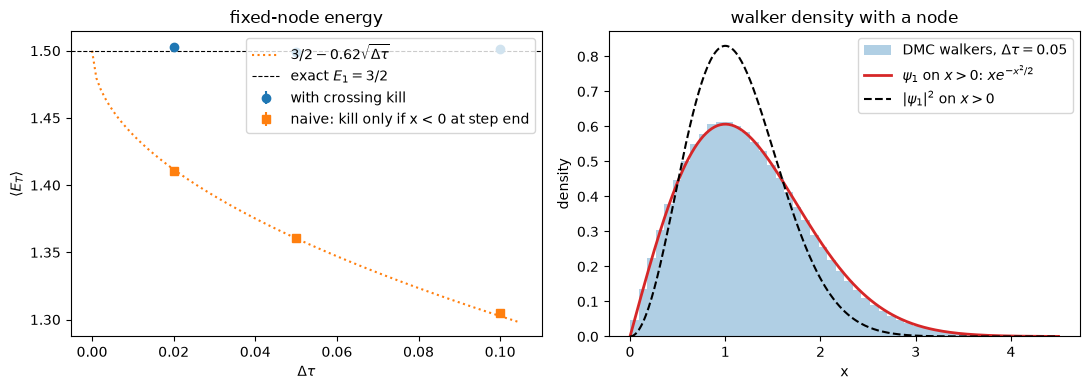

crossing=True  dtau =  0.1:  E_T = 1.5013 ± 0.0015   <V> = 0.9529
crossing=True  dtau = 0.05:  E_T = 1.4989 ± 0.0011   <V> = 0.9762
crossing=True  dtau = 0.02:  E_T = 1.5031 ± 0.0010   <V> = 0.9913
crossing=False dtau =  0.1:  E_T = 1.3047 ± 0.0013   <V> = 0.8112
crossing=False dtau = 0.05:  E_T = 1.3605 ± 0.0012   <V> = 0.8704
crossing=False dtau = 0.02:  E_T = 1.4107 ± 0.0011   <V> = 0.9188
naive error scales as dtau^0.49
<x> = 1.238   psi_1 density: sqrt(pi/2) = 1.253   |psi_1|^2: 1.128
CHECK 5a (crossing-corrected E_T within 3 sigma of 3/2 at every dtau): PASS
CHECK 5b (naive node error ~ sqrt(dtau): fitted power in [0.4, 0.6]): PASS
CHECK 5c (<x> within 2% of the psi_1 value sqrt(pi/2)): PASS


In [10]:
dtN = np.array([0.1, 0.05, 0.02])
node_runs = {}
for crossing in (False, True):
    out = []
    for i, d in enumerate(dtN):
        burn = int(10 / d)
        r = run(harmonic, rng.uniform(0.1, 4, N_T), d, int(400 / d), N_T, seed=60 + i + 10 * crossing,
                node=True, crossing=crossing, keep_from=burn, keep_every=max(1, int(0.5 / d)))
        out.append((r, measure(r, burn)))
    node_runs[crossing] = out
NE = {c: np.array([m["ET"] for _, m in node_runs[c]]).T for c in node_runs}
NV = {c: np.array([m["Vmean"] for _, m in node_runs[c]]).T for c in node_runs}

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4))
a1.errorbar(dtN, NE[True][0], NE[True][1], fmt="o", color="C0", label="with crossing kill")
a1.errorbar(dtN, NE[False][0], NE[False][1], fmt="s", color="C1", label="naive: kill only if x < 0 at step end")
gg = np.linspace(0, 0.105, 100)
c_sqrt = np.mean((1.5 - NE[False][0]) / np.sqrt(dtN))
a1.plot(gg, 1.5 - c_sqrt * np.sqrt(gg), "C1:", label=rf"$3/2 - {c_sqrt:.2f}\sqrt{{\Delta\tau}}$")
a1.axhline(1.5, ls="--", color="k", lw=0.8, label=r"exact $E_1 = 3/2$")
a1.set_xlabel(r"$\Delta\tau$"); a1.set_ylabel(r"$\langle E_T\rangle$"); a1.legend(); a1.set_title("fixed-node energy")
xs1 = node_runs[True][1][0]["samples"][:, 0]
xg = np.linspace(0, 4.5, 300)
c1, e1 = np.histogram(xs1, bins=50, range=(0, 4.5), density=True)
a2.stairs(c1, e1, fill=True, alpha=0.35, color="C0", label="DMC walkers, $\\Delta\\tau = 0.05$")
a2.plot(xg, psi1_half(xg), color="C3", lw=2, label=r"$\psi_1$ on $x>0$: $x e^{-x^2/2}$")
a2.plot(xg, 4 / np.sqrt(np.pi) * xg**2 * np.exp(-xg**2), "k--", lw=1.5, label=r"$|\psi_1|^2$ on $x>0$")
a2.set_xlabel("x"); a2.set_ylabel("density"); a2.legend(); a2.set_title("walker density with a node")
plt.tight_layout(); plt.show()

for c in (True, False):
    for d, a, b, v in zip(dtN, *NE[c], NV[c][0]):
        print(f"crossing={str(c):5s} dtau = {d:4}:  E_T = {a:.4f} ± {b:.4f}   <V> = {v:.4f}")
slope = np.polyfit(np.log(dtN), np.log(1.5 - NE[False][0]), 1)[0]
print(f"naive error scales as dtau^{slope:.2f}")
m1c, e1c = np.mean(xs1), np.sqrt(np.pi / 2)
print(f"<x> = {m1c:.3f}   psi_1 density: sqrt(pi/2) = {e1c:.3f}   |psi_1|^2: {2 / np.sqrt(np.pi):.3f}")
check("5a (crossing-corrected E_T within 3 sigma of 3/2 at every dtau)", np.all(np.abs(NE[True][0] - 1.5) < 3 * NE[True][1]))
check("5b (naive node error ~ sqrt(dtau): fitted power in [0.4, 0.6])", 0.4 < slope < 0.6)
check("5c (<x> within 2% of the psi_1 value sqrt(pi/2))", abs(m1c / e1c - 1) < 0.02)

The naive node rule has an error that goes like $\sqrt{\Delta\tau}$. That is the typical distance a
walker diffuses in one step, and so the width of the layer next to the node where missed crossings
happen. It is far worse than the $\Delta\tau^2$ of the bulk. The crossing kill removes it. What is
left is the $O(\Delta\tau^2)$ of the bulk, which is below the error bars here.

The same trick underlies fixed-node DMC for many-electron systems. There the node is not known.
Guessing it costs a fixed-node error, and that is the price of avoiding the sign problem.

## 6. Summary of checks

In [11]:
for name, ok in checks.items():
    print(f"{'PASS' if ok else 'FAIL'}  {name}")
print(f"\n{sum(checks.values())}/{len(checks)} passed")

PASS  1a (E_T within 4 sigma of asinh(dtau/2)/dtau)
PASS  1b (<V> within 4 sigma of s/2)
PASS  1c (population mean within 5% of target after the transient)
PASS  2a (walker variance within 1% of s(dtau))
PASS  2b (histogram 10x closer to psi_0 than to |psi_0|^2)
PASS  3a (every <V> point within 3 sigma of s/2)
PASS  3b (every E_T point within 3 sigma of asinh formula)
PASS  3c (<V> quadratic extrapolation within 3 sigma of 1/2)
PASS  3d (E_T extrapolation in dtau^2 within 3 sigma of 1/2)
PASS  4a (<V> extrapolation within 3 sigma of -1/2)
PASS  4b (E_T extrapolation within 3 sigma of -1/2)
PASS  4c (at dtau = 0.02, caps 3 and 50 agree with cap 10 within 3 sigma)
PASS  4d (at dtau = 0.08 the cap does bite: caps 3 and 50 differ by > 3 sigma)
PASS  4e (<r> within 2% of 3, the psi_0 value)
PASS  4f (radial histogram 10x closer to psi_0 than to |psi_0|^2)
PASS  5a (crossing-corrected E_T within 3 sigma of 3/2 at every dtau)
PASS  5b (naive node error ~ sqrt(dtau): fitted power in [0.4, 0.6]